<a href="https://colab.research.google.com/github/Mutaqie/Latihan-Machine-Learning/blob/main/Pertemuan%205/Latihan_5_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
RANDOM_STATE = 42

In [ ]:
#1. Muat Dataset Breast Cancer


In [2]:
FILE = 'beast_cancer.csv'

if not os.path.exists(FILE):
    from google.colab import files
    uploaded = files.upload()          # pilih file beast_cancer.csv
    FILE = list(uploaded.keys())[0]

df = pd.read_csv(FILE)
print("Ukuran data mentah:", df.shape)
df.head()

Ukuran data mentah: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [3]:
# Buang kolom yang tidak dipakai
df = df.drop(columns=[c for c in ['id', 'Unnamed: 32'] if c in df.columns])

# Encode label
df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})

print("Ukuran setelah dibersihkan:", df.shape)
print("Missing value total      :", df.isna().sum().sum())
print("\nDistribusi kelas (0 = Benign, 1 = Malignant):")
print(df['diagnosis'].value_counts())
print((df['diagnosis'].value_counts(normalize=True) * 100).round(2).astype(str) + ' %')

Ukuran setelah dibersihkan: (569, 31)
Missing value total      : 0

Distribusi kelas (0 = Benign, 1 = Malignant):
diagnosis
0    357
1    212
Name: count, dtype: int64
diagnosis
0    62.74 %
1    37.26 %
Name: proportion, dtype: object


In [ ]:
#2. Split Stratified 80:20

In [4]:
X = df.drop(columns='diagnosis')
y = df['diagnosis']
feature_names = X.columns.tolist()
class_names = ['Benign', 'Malignant']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f"Data latih : {X_train.shape[0]} sampel")
print(f"Data uji   : {X_test.shape[0]} sampel")
print("\nProporsi kelas Malignant (stratified harus mirip):")
print(f"  seluruh data : {y.mean():.3f}")
print(f"  train        : {y_train.mean():.3f}")
print(f"  test         : {y_test.mean():.3f}")

Data latih : 455 sampel
Data uji   : 114 sampel

Proporsi kelas Malignant (stratified harus mirip):
  seluruh data : 0.373
  train        : 0.374
  test         : 0.368


In [ ]:
#3 & 4. Uji max_depth dan min_samples_leaf

In [5]:
depth_list = [2, 4, 6, None]
leaf_list  = [1, 5, 10]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []

for d in depth_list:
    for leaf in leaf_list:
        model = DecisionTreeClassifier(max_depth=d, min_samples_leaf=leaf,
                                       random_state=RANDOM_STATE)
        cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy')

        model.fit(X_train, y_train)
        acc_train = accuracy_score(y_train, model.predict(X_train))
        acc_test  = accuracy_score(y_test,  model.predict(X_test))

        rows.append({
            'max_depth': 'None' if d is None else d,
            'min_samples_leaf': leaf,
            'acc_train': acc_train,
            'acc_cv_mean': cv_scores.mean(),
            'acc_cv_std': cv_scores.std(),
            'acc_test': acc_test,
            'gap_train_test': acc_train - acc_test,
            'gap_train_cv': acc_train - cv_scores.mean(),
            'n_leaf': model.get_n_leaves(),
            'depth_aktual': model.get_depth(),
        })

hasil = pd.DataFrame(rows)
print("TABEL PARAMETER DAN HASIL (12 kombinasi)")
hasil.round(4)

TABEL PARAMETER DAN HASIL (12 kombinasi)


,max_depth,min_samples_leaf,acc_train,acc_cv_mean,acc_cv_std,acc_test,gap_train_test,gap_train_cv,n_leaf,depth_aktual
0,2,1,0.9538,0.9209,0.0245,0.9211,0.0328,0.0330,4,2
1,2,5,0.9538,0.9297,0.0237,0.9211,0.0328,0.0242,4,2
2,2,10,0.9473,0.9253,0.0254,0.9298,0.0174,0.0220,4,2
3,4,1,0.9824,0.9209,0.0383,0.9123,0.0701,0.0615,13,4
4,4,5,0.9626,0.9253,0.0306,0.9035,0.0591,0.0374,9,4
5,4,10,0.9582,0.9231,0.0260,0.9123,0.0460,0.0352,8,4
6,6,1,0.9934,0.9209,0.0389,0.9211,0.0724,0.0725,19,6
7,6,5,0.9626,0.9253,0.0306,0.9035,0.0591,0.0374,12,6
8,6,10,0.9582,0.9231,0.0260,0.9123,0.0460,0.0352,10,6
9,None,1,1.0000,0.9231,0.0326,0.9298,0.0702,0.0769,24,8


In [ ]:
#5. Bandingkan Train, CV, Test, dan Leaf

In [6]:
# Urutkan berdasarkan CV (tertinggi). Jika sama, pilih pohon dengan leaf paling sedikit.
tabel = hasil.sort_values(['acc_cv_mean', 'n_leaf'], ascending=[False, True]).reset_index(drop=True)
tabel.index = tabel.index + 1
tabel.index.name = 'peringkat_CV'

tampil = tabel[['max_depth', 'min_samples_leaf', 'acc_train', 'acc_cv_mean',
                'acc_test', 'gap_train_test', 'n_leaf']].copy()
tampil.columns = ['max_depth', 'min_leaf', 'Akurasi Train', 'Akurasi CV',
                  'Akurasi Test', 'Gap Train-Test', 'Jumlah Leaf']
print("DIURUTKAN BERDASARKAN AKURASI CV")
tampil.round(4)

DIURUTKAN BERDASARKAN AKURASI CV


,max_depth,min_leaf,Akurasi Train,Akurasi CV,Akurasi Test,Gap Train-Test,Jumlah Leaf
peringkat_CV,,,,,,,
1,2,5,0.9538,0.9297,0.9211,0.0328,4
2,2,10,0.9473,0.9253,0.9298,0.0174,4
3,4,5,0.9626,0.9253,0.9035,0.0591,9
4,6,5,0.9626,0.9253,0.9035,0.0591,12
5,None,5,0.9626,0.9253,0.9035,0.0591,14
6,4,10,0.9582,0.9231,0.9123,0.0460,8
7,6,10,0.9582,0.9231,0.9123,0.0460,10
8,None,10,0.9582,0.9231,0.9123,0.0460,10
9,None,1,1.0000,0.9231,0.9298,0.0702,24


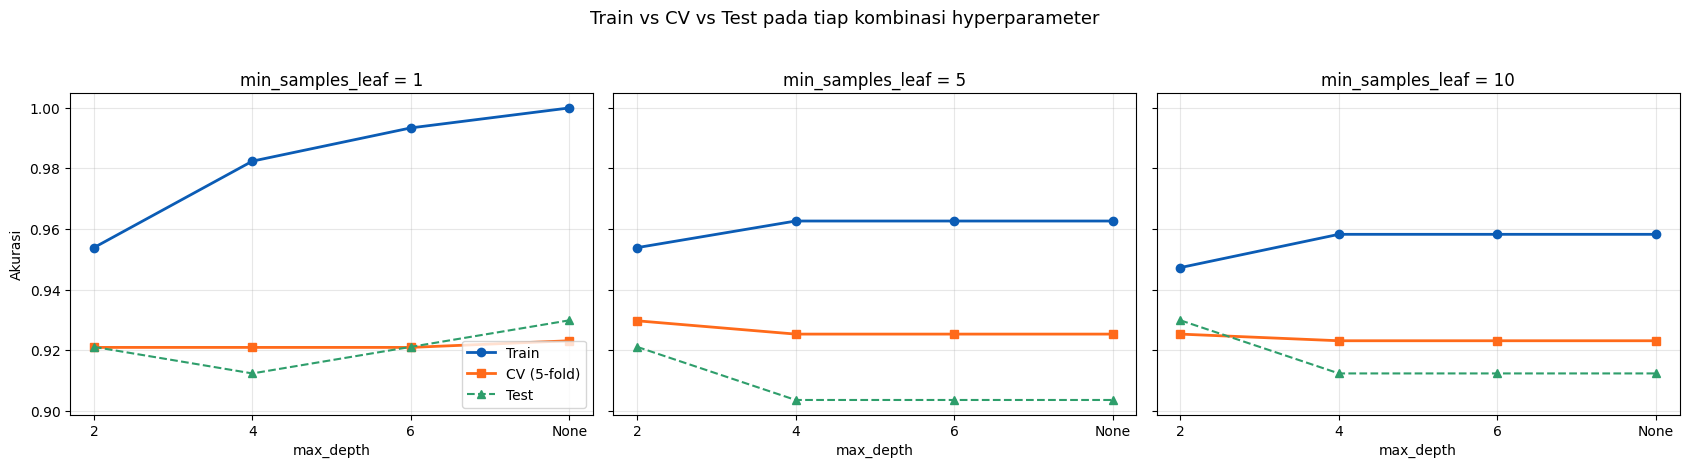

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
hasil_plot = hasil.copy()
hasil_plot['depth_label'] = hasil_plot['max_depth'].astype(str)
urut = ['2', '4', '6', 'None']

for ax, leaf in zip(axes, leaf_list):
    sub = hasil_plot[hasil_plot['min_samples_leaf'] == leaf].set_index('depth_label').loc[urut]
    ax.plot(urut, sub['acc_train'],   'o-', label='Train',      color='#0B5CB5', lw=2)
    ax.plot(urut, sub['acc_cv_mean'], 's-', label='CV (5-fold)', color='#FF6A1A', lw=2)
    ax.plot(urut, sub['acc_test'],    '^--', label='Test',       color='#2E9E6B', lw=1.5)
    ax.set_title(f'min_samples_leaf = {leaf}')
    ax.set_xlabel('max_depth')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Akurasi')
axes[0].legend(loc='lower right')
plt.suptitle('Train vs CV vs Test pada tiap kombinasi hyperparameter', y=1.03, fontsize=13)
plt.tight_layout()
plt.show()

In [ ]:
#6. Pilih Model Terbaik (berdasarkan CV)

In [8]:
terbaik = tabel.iloc[0]
best_depth = None if terbaik['max_depth'] == 'None' else int(terbaik['max_depth'])
best_leaf  = int(terbaik['min_samples_leaf'])

print("MODEL TERPILIH (kriteria: akurasi CV tertinggi, leaf paling sedikit jika seri)")
print(f"  max_depth        : {best_depth}")
print(f"  min_samples_leaf : {best_leaf}")
print(f"  Akurasi CV       : {terbaik['acc_cv_mean']:.4f} (+/- {terbaik['acc_cv_std']:.4f})")

MODEL TERPILIH (kriteria: akurasi CV tertinggi, leaf paling sedikit jika seri)
  max_depth        : 2
  min_samples_leaf : 5
  Akurasi CV       : 0.9297 (+/- 0.0237)


In [ ]:
#7. Evaluasi Akhir Model Terpilih

In [9]:
final_tree = DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=best_leaf,
                                    random_state=RANDOM_STATE)
final_tree.fit(X_train, y_train)

acc_train_final = accuracy_score(y_train, final_tree.predict(X_train))
acc_cv_final    = cross_val_score(final_tree, X_train, y_train, cv=cv, scoring='accuracy').mean()
y_pred          = final_tree.predict(X_test)
acc_test_final  = accuracy_score(y_test, y_pred)
gap_final       = acc_train_final - acc_test_final

ringkasan = pd.DataFrame({
    'Parameter / Metrik': ['max_depth', 'min_samples_leaf', 'Akurasi train', 'Akurasi CV',
                           'Akurasi test final', 'Gap train-test', 'Jumlah leaf node', 'Kedalaman aktual'],
    'Nilai': [str(best_depth), str(best_leaf), f'{acc_train_final:.4f}', f'{acc_cv_final:.4f}',
              f'{acc_test_final:.4f}', f'{gap_final:.4f}',
              str(final_tree.get_n_leaves()), str(final_tree.get_depth())]
})
print("OUTPUT WAJIB: RINGKASAN MODEL TERPILIH")
ringkasan

OUTPUT WAJIB: RINGKASAN MODEL TERPILIH


,Parameter / Metrik,Nilai
0,max_depth,2
1,min_samples_leaf,5
2,Akurasi train,0.9538
3,Akurasi CV,0.9297
4,Akurasi test final,0.9211
5,Gap train-test,0.0328
6,Jumlah leaf node,4
7,Kedalaman aktual,2


Classification report (data test):

              precision    recall  f1-score   support

      Benign     0.8987    0.9861    0.9404        72
   Malignant     0.9714    0.8095    0.8831        42

    accuracy                         0.9211       114
   macro avg     0.9351    0.8978    0.9118       114
weighted avg     0.9255    0.9211    0.9193       114



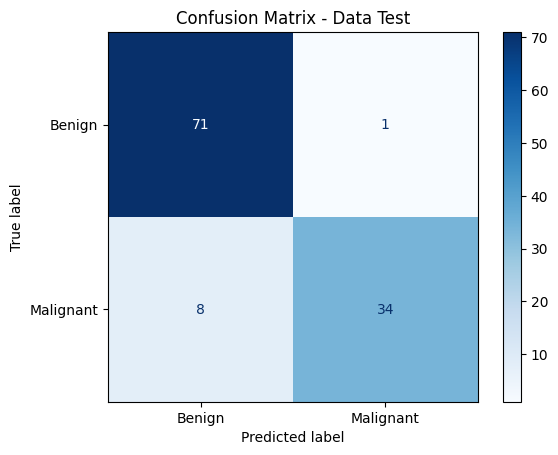

In [10]:
print("Classification report (data test):\n")
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix - Data Test')
plt.show()

In [ ]:
#8. Visualisasi Pohon Terpilih

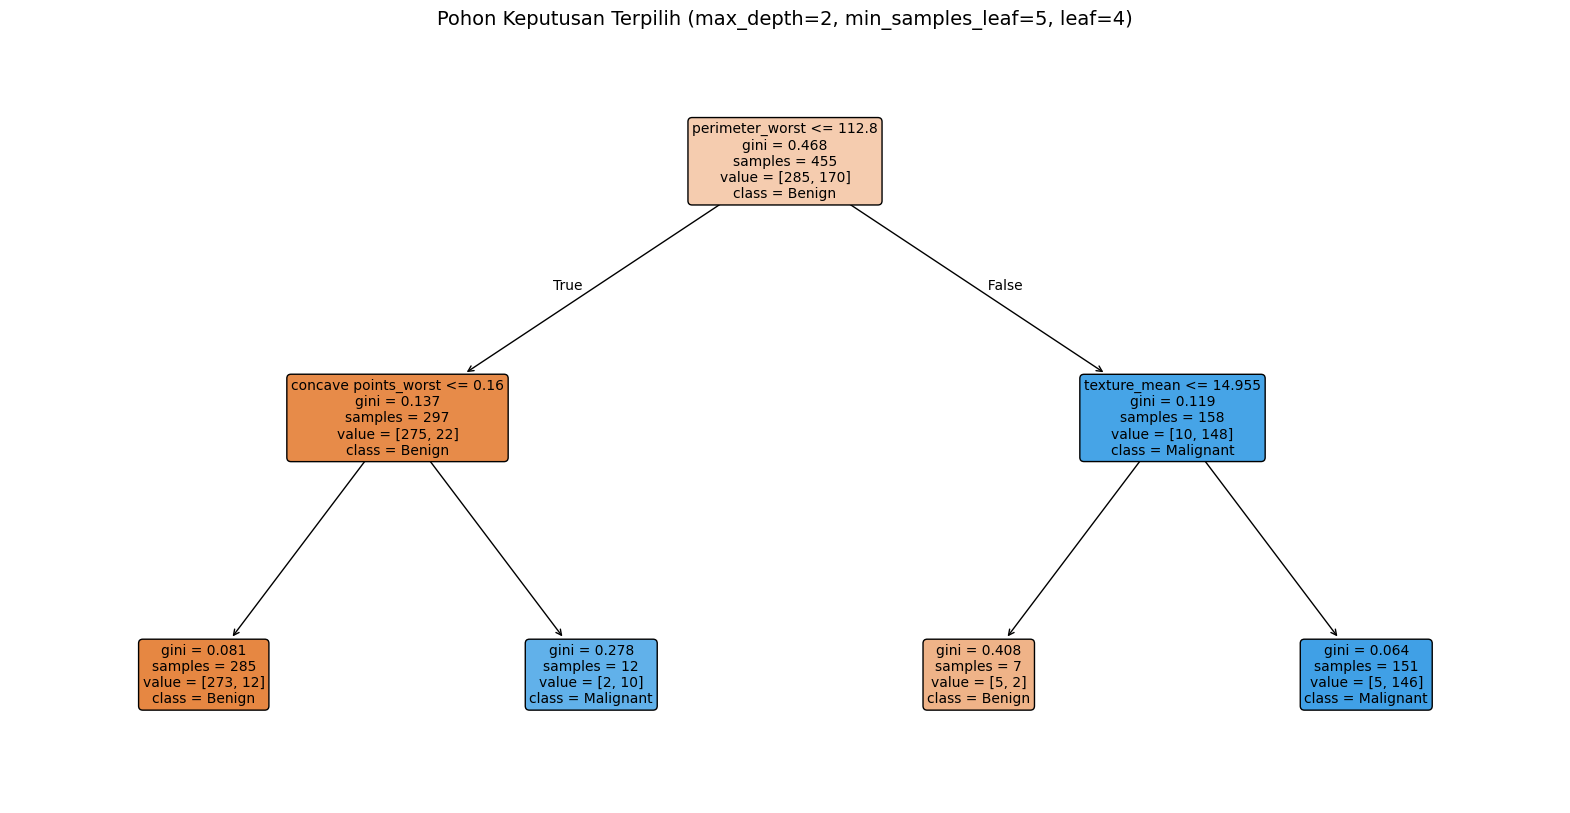

In [11]:
plt.figure(figsize=(20, 10))
plot_tree(final_tree,
          feature_names=feature_names,
          class_names=class_names,
          filled=True, rounded=True, impurity=True, proportion=False, fontsize=10)
plt.title(f'Pohon Keputusan Terpilih (max_depth={best_depth}, min_samples_leaf={best_leaf}, '
          f'leaf={final_tree.get_n_leaves()})', fontsize=14)
plt.show()

In [12]:
print("ATURAN POHON DALAM BENTUK TEKS\n")
print(export_text(final_tree, feature_names=feature_names))

ATURAN POHON DALAM BENTUK TEKS

|--- perimeter_worst <= 112.80
|   |--- concave points_worst <= 0.16
|   |   |--- class: 0
|   |--- concave points_worst >  0.16
|   |   |--- class: 1
|--- perimeter_worst >  112.80
|   |--- texture_mean <= 14.95
|   |   |--- class: 0
|   |--- texture_mean >  14.95
|   |   |--- class: 1



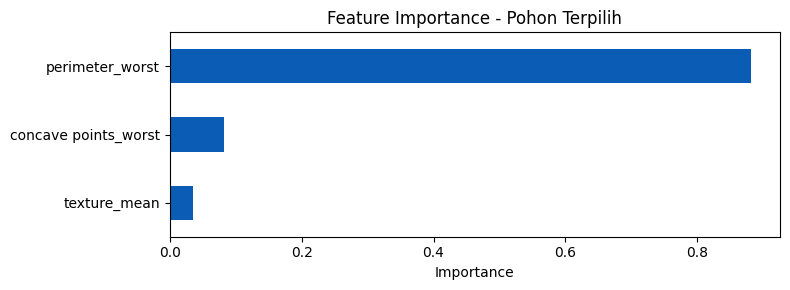

In [13]:
imp = pd.Series(final_tree.feature_importances_, index=feature_names)
imp = imp[imp > 0].sort_values()
plt.figure(figsize=(8, max(3, 0.4 * len(imp))))
imp.plot(kind='barh', color='#0B5CB5')
plt.title('Feature Importance - Pohon Terpilih')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

In [ ]:
#9. Perbandingan Pohon Penuh vs Pohon Dibatasi

In [14]:
tree_full = DecisionTreeClassifier(random_state=42)
tree_pruned = DecisionTreeClassifier(
    max_depth=4,
    min_samples_leaf=5,
    random_state=42
)

rekap = []
for name, model in [
    ("Full", tree_full),
    ("Pruned", tree_pruned)
]:
    model.fit(X_train, y_train)
    tr = accuracy_score(y_train, model.predict(X_train))
    te = accuracy_score(y_test, model.predict(X_test))
    print(name, round(tr, 4), round(te, 4), "gap =", round(tr - te, 4))
    rekap.append({'Model': name, 'Train': tr, 'Test': te, 'Gap': tr - te,
                  'Kedalaman': model.get_depth(), 'Jumlah Leaf': model.get_n_leaves()})

pd.DataFrame(rekap).round(4)

Full 1.0 0.9298 gap = 0.0702
Pruned 0.9626 0.9035 gap = 0.0591


,Model,Train,Test,Gap,Kedalaman,Jumlah Leaf
0,Full,1.0000,0.9298,0.0702,8,24
1,Pruned,0.9626,0.9035,0.0591,4,9


In [ ]:
#10. Post-pruning: Cost-Complexity Pruning (opsional, sesuai materi Cα(T) = R(T) + α|T|)

Alpha terbaik (CV) : 0.013644
Akurasi CV         : 0.9231
Jumlah leaf        : 4


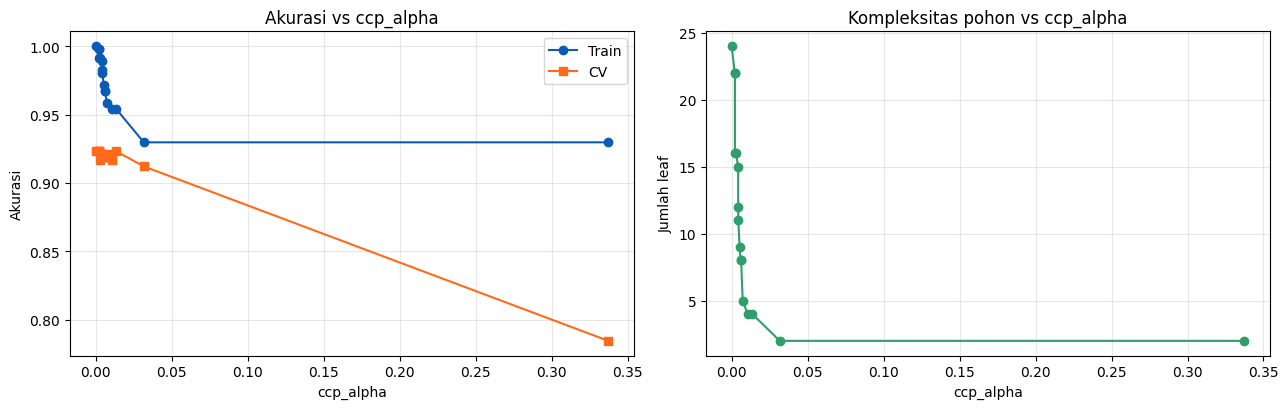

In [15]:
path = DecisionTreeClassifier(random_state=RANDOM_STATE).cost_complexity_pruning_path(X_train, y_train)
alphas = np.unique(np.round(path.ccp_alphas, 6))
alphas = alphas[alphas >= 0]

cv_alpha, train_alpha, leaf_alpha = [], [], []
for a in alphas:
    m = DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=a)
    cv_alpha.append(cross_val_score(m, X_train, y_train, cv=cv).mean())
    m.fit(X_train, y_train)
    train_alpha.append(m.score(X_train, y_train))
    leaf_alpha.append(m.get_n_leaves())

cv_arr = np.array(cv_alpha)
best_i = int(np.where(cv_arr == cv_arr.max())[0][-1])   # jika seri, pilih alpha terbesar (pohon paling sederhana)
print(f"Alpha terbaik (CV) : {alphas[best_i]:.6f}")
print(f"Akurasi CV         : {cv_alpha[best_i]:.4f}")
print(f"Jumlah leaf        : {leaf_alpha[best_i]}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].plot(alphas, train_alpha, 'o-', label='Train', color='#0B5CB5')
ax[0].plot(alphas, cv_alpha, 's-', label='CV', color='#FF6A1A')
ax[0].set_xlabel('ccp_alpha'); ax[0].set_ylabel('Akurasi'); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[0].set_title('Akurasi vs ccp_alpha')
ax[1].plot(alphas, leaf_alpha, 'o-', color='#2E9E6B')
ax[1].set_xlabel('ccp_alpha'); ax[1].set_ylabel('Jumlah leaf'); ax[1].grid(alpha=0.3)
ax[1].set_title('Kompleksitas pohon vs ccp_alpha')
plt.tight_layout(); plt.show()

In [ ]:
#11. Kesimpulan dan Jawaban Pertanyaan Analisis

In [16]:
top_train = hasil.sort_values(['acc_train', 'n_leaf'], ascending=[False, False]).iloc[0]
print("Pohon dengan train tertinggi :", f"depth={top_train['max_depth']}, min_leaf={top_train['min_samples_leaf']}",
      f"| train={top_train['acc_train']:.4f} | CV={top_train['acc_cv_mean']:.4f} | test={top_train['acc_test']:.4f}",
      f"| gap={top_train['gap_train_test']:.4f} | leaf={top_train['n_leaf']}")
print("Pohon terpilih berdasarkan CV :", f"depth={best_depth}, min_leaf={best_leaf}",
      f"| train={acc_train_final:.4f} | CV={acc_cv_final:.4f} | test={acc_test_final:.4f}",
      f"| gap={gap_final:.4f} | leaf={final_tree.get_n_leaves()}")

Pohon dengan train tertinggi : depth=None, min_leaf=1 | train=1.0000 | CV=0.9231 | test=0.9298 | gap=0.0702 | leaf=24
Pohon terpilih berdasarkan CV : depth=2, min_leaf=5 | train=0.9538 | CV=0.9297 | test=0.9211 | gap=0.0328 | leaf=4
